# CA1 Microcircuit with UI

![PAC System Workflow](PACSystem.png)

#### Requirements

In [1]:
! pip install ipywidgets > /dev/null 2>&1
!pip install -U pyunicore pactools > /dev/null 2>&1
! jupyter nbextension enable --py widgetsnbextension

usage: jupyter [-h] [--json] [--debug]
               [--version | --config-dir | --data-dir | --runtime-dir |
               --paths | subcommand]

Jupyter: Interactive Computing

positional arguments:
  subcommand     the subcommand to launch

options:
  -h, --help     show this help message and exit
  --version      show the versions of core jupyter packages and exit
  --config-dir   show Jupyter config dir
  --data-dir     show Jupyter data dir
  --runtime-dir  show Jupyter runtime dir
  --paths        show all Jupyter paths. Add --json for machine-readable
                 format.
  --json         output paths as machine-readable json
  --debug        output debug information about paths

Available subcommands: kernel kernelspec migrate run troubleshoot

Jupyter command `jupyter-nbextension` not found.


In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from collections import OrderedDict
import os

# Set default figure style
plt.rcParams.update({
    'figure.figsize': (12, 4),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})

print("Imports ready ✓")

Imports ready ✓


## Job submit

In [3]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import json
from datetime import datetime

# ============================================================
# CONFIG
# ============================================================
# (no active job limit)
TRACKED_JOBS_FILE = 'tgp_ui_jobs.json'

TERMINAL_STATUSES = {
    'SUCCESSFUL', 'FAILED', 'ABORTED', 'CANCELLED', 'CANCELED',
    'DONE', 'FINISHED'
}

# In-memory objects for the current kernel only
USER_JOB_OBJECTS = {}
CLS_JOB_OBJECTS = {}

# Persisted registry (metadata only)
JOB_REGISTRY = []


# ============================================================
# PARAMETER DEFINITIONS
# ============================================================
# 10 educationally-relevant parameters from the Ponzi et al. (2023) model.
# Each entry: (cfg name, label, default, min, max, type, description)
PARAM_DEFS = {
    'olm_pc_gaba_tau': {
        'label': 'OLM→PYR GABA decay time constant (ms)',
        'default': 10.3, 'min': 8.0, 'max': 18.0, 'type': float,
        'desc': 'Inhibitory synapse kinetics: longer decay → slower theta, stronger PAC.'
    },
    'olm_pc_conprob': {
        'label': 'OLM→PYR connection probability',
        'default': 0.4, 'min': 0.2, 'max': 0.6, 'type': float,
        'desc': 'Higher → stronger OLM drive on PYR distal dendrites → more robust theta-gamma PAC.'
    },
    'olm2pcDep': {
        'label': 'OLM→PYR short-term depression time constant (ms)',
        'default': 1770.0, 'min': 500.0, 'max': 3000.0, 'type': float,
        'desc': 'Higher D → deeper depression → PYR escapes inhibition faster → theta may speed up.'
    },
    'olm2pcFac': {
        'label': 'OLM→PYR short-term facilitation time constant (ms)',
        'default': 6.0, 'min': 0.0, 'max': 50.0, 'type': float,
        'desc': 'Higher → stronger later IPSPs on PYR → may slow theta and increase gamma synchrony.'
    },
    'pc_olm_conprob': {
        'label': 'PYR→OLM connection probability',
        'default': 0.35, 'min': 0.15, 'max': 0.55, 'type': float,
        'desc': 'Excitatory feedback: most direct lever on the OLM-PYR feedback loop and PAC.'
    },
    'pv_pc_conprob': {
        'label': 'PVBC→PYR connection probability',
        'default': 0.25, 'min': 0.1, 'max': 0.5, 'type': float,
        'desc': 'Perisomatic inhibition: higher → cleaner, stronger gamma oscillations.'
    },
    'pvbc2pcDep': {
        'label': 'PVBC→PYR STP depression time constant (ms)',
        'default': 965.0, 'min': 400.0, 'max': 1500.0, 'type': float,
        'desc': 'Higher D → longer inhibitory window per gamma cycle → lower gamma frequency.'
    },
    'pc_pv_conprob': {
        'label': 'PYR→PVBC connection probability',
        'default': 0.35, 'min': 0.15, 'max': 0.55, 'type': float,
        'desc': 'Excitatory drive to fast interneurons: higher → stronger PING gamma.'
    },
    'pc_pc_conprob': {
        'label': 'PYR→PYR recurrent connection probability',
        'default': 0.35, 'min': 0.05, 'max': 0.5, 'type': float,
        'desc': 'Recurrent excitation: illustrates E-I balance; too high → runaway activity.'
    },
    'artifperpyr': {
        'label': 'Number of SC input fibers per PYR cell (SCIL proxy)',
        'default': 76, 'min': 40, 'max': 150, 'type': int,
        'desc': 'Main control of the operating point. PAC emerges roughly between 60-110.'
    },
}

# Defaults when the notebook first loads
DEFAULT_PARAM = 'olm_pc_gaba_tau'
DEFAULT_VALUES_STR = '8.3, 9, 10.3, 11'


# ============================================================
# REGISTRY HELPERS
# ============================================================
def now_iso():
    return datetime.now().isoformat(timespec='seconds')

def clean_props(props):
    props = dict(props)
    for key in ['submissionPreferences', '_links', 'tags']:
        props.pop(key, None)
    return props

def normalize_cls_props(data, expected_job_id=None, allow_empty=False):
    """Normalize CLS API responses to a single dict."""
    if isinstance(data, dict):
        for key in ('results', 'items', 'data'):
            if key in data and isinstance(data[key], list):
                data = data[key]
                break
            if key in data and isinstance(data[key], dict):
                return data[key]
        else:
            return data

    if isinstance(data, list):
        if not data:
            if allow_empty:
                return None
            raise RuntimeError('CLS API returned an empty job list.')

        if expected_job_id is not None:
            for item in data:
                if isinstance(item, dict) and str(item.get('id', item.get('job_id', ''))) == str(expected_job_id):
                    return item

        first = data[0]
        if isinstance(first, dict):
            return first

        raise RuntimeError(
            f'CLS API returned a list, but entries are not dicts: {type(first).__name__}'
        )

    raise RuntimeError(f'Unsupported CLS API response type: {type(data).__name__}')

def summarize_props(mode, props):
    if mode == 'Own user':
        return {
            'name': props.get('name', 'N/A'),
            'status': props.get('status', 'N/A'),
            'queue': props.get('queue', 'N/A'),
            'submissionTime': props.get('submissionTime', 'N/A'),
            'terminationTime': props.get('terminationTime', 'N/A'),
            'statusMessage': props.get('statusMessage', '')
        }
    else:
        props = normalize_cls_props(props)
        return {
            'name': props.get('title', props.get('name', 'N/A')),
            'status': props.get('status', props.get('job_status', 'N/A')),
            'queue': props.get('queue', props.get('hpc', 'N/A')),
            'submissionTime': props.get('submission_time', props.get('created_at', 'N/A')),
            'terminationTime': props.get('termination_time', props.get('finished_at', 'N/A')),
            'statusMessage': props.get('status_message', props.get('message', ''))
        }

def is_terminal_status(status):
    return str(status).upper() in TERMINAL_STATUSES

def save_registry():
    with open(TRACKED_JOBS_FILE, 'w') as f:
        json.dump(JOB_REGISTRY, f, indent=2)

def load_registry():
    global JOB_REGISTRY
    try:
        with open(TRACKED_JOBS_FILE, 'r') as f:
            JOB_REGISTRY = json.load(f)
    except FileNotFoundError:
        JOB_REGISTRY = []
    except Exception:
        JOB_REGISTRY = []

def upsert_job_record(record):
    global JOB_REGISTRY
    updated = False
    for i, existing in enumerate(JOB_REGISTRY):
        if existing['job_id'] == record['job_id']:
            JOB_REGISTRY[i].update(record)
            updated = True
            break
    if not updated:
        JOB_REGISTRY.append(record)
    save_registry()
    refresh_job_selector()

def get_job_record(job_id):
    for rec in JOB_REGISTRY:
        if rec['job_id'] == job_id:
            return rec
    return None

def count_active_jobs():
    return sum(1 for rec in JOB_REGISTRY if not is_terminal_status(rec.get('status', 'N/A')))

def refresh_job_selector():
    options = [('— select a tracked job —', '')]
    for rec in JOB_REGISTRY:
        label = f"[{rec.get('status', 'N/A')}] {rec['mode']} | {rec['title']} | {rec['job_id']}"
        options.append((label, rec['job_id']))
    dropdown_job_select.options = options

def last_log_line_from_props(mode, props):
    if mode == 'Own user':
        log_lines = props.get('log', [])
        return log_lines[-1] if log_lines else ''
    logs = props.get('log', props.get('logs', []))
    if isinstance(logs, list) and logs:
        return logs[-1]
    return ''

def print_job_summary(record, props, show_json=False):
    summary = summarize_props(record['mode'], props)
    print("Job ID:", record['job_id'])
    print("Mode:", record['mode'])
    print("Title:", record['title'])
    if record.get('param_name'):
        print("Parameter:", record['param_name'], "=", record.get('param_value'))
    print("Status:", summary.get('status', 'N/A'))
    print("Queue/HPC:", summary.get('queue', 'N/A'))
    print("Submission time:", summary.get('submissionTime', 'N/A'))
    print("Termination time:", summary.get('terminationTime', 'N/A'))
    print("Status message:", summary.get('statusMessage', ''))
    last_log = last_log_line_from_props(record['mode'], props)
    if last_log:
        print("Last log line:", last_log)
    if show_json:
        print("\nFull properties:")
        print(json.dumps(props, indent=2))


# ============================================================
# PARAMETER VALIDATION
# ============================================================
def parse_param_values(param_name, values_str):
    """Parse comma-separated values string into a list of correctly-typed values.

    Raises ValueError with a user-friendly message on any problem.
    """
    if param_name not in PARAM_DEFS:
        raise ValueError(f"Unknown parameter: {param_name}")

    spec = PARAM_DEFS[param_name]
    raw_parts = [p.strip() for p in values_str.split(',') if p.strip()]

    if not raw_parts:
        raise ValueError("No values provided. Enter one or more comma-separated numbers.")

    values = []
    for raw in raw_parts:
        try:
            if spec['type'] is int:
                v = int(float(raw))  # tolerate "50" or "50.0"
            else:
                v = float(raw)
        except ValueError:
            raise ValueError(f"'{raw}' is not a valid {spec['type'].__name__}.")

        if v < spec['min'] or v > spec['max']:
            raise ValueError(
                f"Value {v} is outside the biological range "
                f"[{spec['min']}, {spec['max']}] for '{param_name}'."
            )
        values.append(v)

    return values

def format_param_value(param_name, value):
    """Format a parameter value for use in job names / run IDs (no spaces)."""
    spec = PARAM_DEFS[param_name]
    if spec['type'] is int:
        return str(int(value))
    return str(value)


# ============================================================
# OWN USER (UNICORE)
# ============================================================
def get_unicore_client():
    import pyunicore.client as uc_client
    from pyunicore.credentials import OIDCToken

    token = clb_oauth.get_token()
    JUSUF = 'https://zam2125.zam.kfa-juelich.de:9112/JUSUF/rest/core'
    transport = uc_client.Transport(OIDCToken(token))
    client = uc_client.Client(security=transport, site_url=JUSUF)
    return client

def submit_user(job_title, param_name, param_value, output_area):
    """Submit one Own-user UNICORE job with the given parameter value."""
    global USER_JOB_OBJECTS

    val_str = format_param_value(param_name, param_value)
    run_id = f"t42_{param_name}_{val_str}"

    with output_area:
        print(f"[SUBMIT] OWN USER — '{job_title}' | {param_name}={val_str}")

    client = get_unicore_client()

    tags = ['tgp', 'ui', 'jupyter-notebook', 'collab', 'wiki', param_name, val_str]
    pre_command = '/p/project1/icei-hbp-2020-0013/ThetagammaPAC/prepare_job.sh'
    command = './run_uni_ext.sh'
    args = ''
    post_command = ''

    env_vars = {
        f'SIM_PARAM_{param_name.upper()}': str(param_value),
        'SIM_RUNID': run_id,
    }

    job_descriptor = {
        'User precommand': pre_command,
        'Executable': command,
        'Arguments': args,
        'User postcommand': post_command,
        'Name': job_title,
        'Environment': env_vars,
        'Resources': {
            'Project': 'icei-hbp-2020-0013',
            'Nodes': 1,
            'TotalCPUs': 128,
            'CPUsPerNode': 128,
            'Runtime': '3h'
        },
        'Tags': tags
    }

    job = client.new_job(job_descriptor)
    job_id = job.job_id
    USER_JOB_OBJECTS[job_id] = {'job': job, 'client': client}

    props = clean_props(job.properties)
    record = {
        'job_id': job_id,
        'title': job_title,
        'mode': 'Own user',
        'status': props.get('status', 'N/A'),
        'last_checked': now_iso(),
        'summary': summarize_props('Own user', props),
        'param_name': param_name,
        'param_value': val_str,
    }
    upsert_job_record(record)

    with output_area:
        print(f"✅ [USER] Job submitted — ID {job_id}  status={props.get('status', 'N/A')}")

    return job_id

def fetch_user(job_id, output_area, show_json=False):
    record = get_job_record(job_id)
    if record is None:
        with output_area:
            print(f"⚠️ Job ID '{job_id}' is not in the tracked list.")
            print("Own user jobs can only be refreshed here if they were submitted from this notebook session.")
        return

    if job_id not in USER_JOB_OBJECTS:
        with output_area:
            print(f"⚠️ Job '{job_id}' is tracked, but its live UNICORE object is not in memory.")
            print("This usually means the notebook kernel was restarted.")
            print("At this stage, Own user refresh works only for jobs submitted in the current notebook session.")
        return

    job = USER_JOB_OBJECTS[job_id]['job']
    props = clean_props(job.properties)

    record['status'] = props.get('status', 'N/A')
    record['last_checked'] = now_iso()
    record['summary'] = summarize_props('Own user', props)
    upsert_job_record(record)

    with output_area:
        print("✅ Own user status checked")
        print_job_summary(record, props, show_json=show_json)


# ============================================================
# CLS SERVICE ACCOUNT
# ============================================================
def cls_build_headers():
    APP_KEY = 'QdGwy=a~^4zuU2{[=$F5|S<qh;GS7Du,'
    return {
        'Content-Type': 'application/json',
        'Authorization': 'Bearer ' + str(clb_oauth.get_token()),
        'Appkey': APP_KEY,
    }

def submit_cls(job_title, param_name, param_value, output_area):
    """Submit one CLS-Service-Account job with the given parameter value."""
    import requests

    CLS_SA_ROOT_URL = 'https://cls-sa.ebrains-italy.eu'
    PRE_COMMAND = '/p/project1/icei-hbp-2020-0013/ThetagammaPAC/prepare_job.sh'
    EXEC_COMMAND = './run_uni_ext.sh'
    HPC = 'jusuf'
    PROJECT = 'tgp-test-project'

    val_str = format_param_value(param_name, param_value)
    run_id = f"t42_{param_name}_{val_str}"

    # CLS does not offer an Environment field, so we prepend `export` statements
    # to the command so run_uni_ext.sh sees the same SIM_PARAM_* env vars.
    env_prefix = (
        f'export SIM_PARAM_{param_name.upper()}={param_value}; '
        f'export SIM_RUNID={run_id}; '
    )
    COMMAND = f'{env_prefix}{PRE_COMMAND} && {EXEC_COMMAND}'

    payload = {
        'command': COMMAND,
        'hpc': HPC,
        'project': PROJECT,
        'node_number': 2,
        'core_number': 256,
        'runtime': 6.5,
        'title': job_title
    }

    with output_area:
        print(f"[SUBMIT] CLS — '{job_title}' | {param_name}={val_str}")

    r = requests.post(
        url=f'{CLS_SA_ROOT_URL}/job/',
        headers=cls_build_headers(),
        data=json.dumps(payload),
        timeout=360000
    )

    if r.status_code != 201:
        raise RuntimeError(f"CLS submit failed: HTTP {r.status_code} - {r.text}")

    submit_data = normalize_cls_props(r.json(), allow_empty=False)
    job_id = str(submit_data.get('id', submit_data.get('job_id', '')))

    if not job_id:
        raise RuntimeError(f'CLS submit response did not include a job id. Raw response: {submit_data}')

    # Try immediate lookup, but tolerate temporary empty results
    props = None
    try:
        props = get_cls_job(job_id, allow_empty=True)
    except Exception:
        props = None

    if props is None:
        status = 'SUBMITTED'
        summary = {
            'job_id': job_id,
            'name': job_title,
            'status': status,
            'submissionTime': now_iso(),
            'queue': 'N/A',
            'statusMessage': 'Job submitted; details not yet available from CLS API.',
            'last_log': 'Waiting for CLS job record to become visible.'
        }
    else:
        summary = summarize_props('CLS-Service-Account', props)
        status = summary.get('status', 'N/A')

    record = {
        'job_id': job_id,
        'title': job_title,
        'mode': 'CLS-Service-Account',
        'status': status,
        'last_checked': now_iso(),
        'summary': summary,
        'param_name': param_name,
        'param_value': val_str,
    }
    upsert_job_record(record)

    with output_area:
        print(f"✅ [CLS] Job submitted — ID {job_id}  status={status}")

    return job_id

def get_cls_job(job_id, allow_empty=False):
    import requests

    CLS_SA_ROOT_URL = 'https://cls-sa.ebrains-italy.eu'
    PROJECT = 'tgp-test-project'

    query_params = {
        'project': PROJECT,
        'job_id': job_id
    }

    r = requests.get(
        url=f'{CLS_SA_ROOT_URL}/job/',
        headers=cls_build_headers(),
        params=query_params,
        timeout=360000
    )

    if r.status_code != 200:
        raise RuntimeError(f"CLS status check failed: HTTP {r.status_code} - {r.text}")

    return normalize_cls_props(r.json(), expected_job_id=job_id, allow_empty=allow_empty)

def fetch_cls(job_id, output_area, show_json=False):
    record = get_job_record(job_id)
    if record is None:
        with output_area:
            print(f"⚠️ Job ID '{job_id}' is not in the tracked list.")
        return

    props = get_cls_job(job_id, allow_empty=True)

    with output_area:
        if props is None:
            print("ℹ️ CLS job is still not visible in the status API.")
            print("Job ID:", job_id)
            print("Try again in a bit.")
            return

    status = summarize_props('CLS-Service-Account', props).get('status', 'N/A')
    record['status'] = status
    record['last_checked'] = now_iso()
    record['summary'] = summarize_props('CLS-Service-Account', props)
    upsert_job_record(record)

    with output_area:
        print("✅ CLS status checked")
        print_job_summary(record, props, show_json=show_json)


# ============================================================
# GLOBAL REFRESH / LIMITS
# ============================================================
def refresh_all_active_jobs_silent():
    for rec in JOB_REGISTRY:
        status = rec.get('status', 'N/A')
        if is_terminal_status(status):
            continue
        job_id = rec['job_id']
        try:
            if rec['mode'] == 'Own user' and job_id in USER_JOB_OBJECTS:
                job = USER_JOB_OBJECTS[job_id]['job']
                props = clean_props(job.properties)
                rec['status'] = props.get('status', 'N/A')
                rec['last_checked'] = now_iso()
                rec['summary'] = summarize_props('Own user', props)
            elif rec['mode'] == 'CLS-Service-Account':
                props = get_cls_job(job_id)
                rec['status'] = summarize_props('CLS-Service-Account', props).get('status', 'N/A')
                rec['last_checked'] = now_iso()
                rec['summary'] = summarize_props('CLS-Service-Account', props)
        except Exception:
            pass
    save_registry()
    refresh_job_selector()

def check_submit_allowed():
    refresh_all_active_jobs_silent()
    active = [rec for rec in JOB_REGISTRY if not is_terminal_status(rec.get('status', 'N/A'))]
    return active


# ============================================================
# UI
# ============================================================
dropdown_mode = widgets.Dropdown(
    options=['Own user', 'CLS-Service-Account'],
    value='Own user',
    description='Select mode:',
    style={'description_width': 'initial'}
)

text_job_title = widgets.Text(
    value='',
    placeholder='Job title (a suffix will be added per value)',
    description='Title:'
)

# --- Parameter-sweep widgets ---
dropdown_param = widgets.Dropdown(
    options=[(f"{k} — {v['label']}", k) for k, v in PARAM_DEFS.items()],
    value=DEFAULT_PARAM,
    description='Parameter:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='95%')
)

text_param_values = widgets.Text(
    value=DEFAULT_VALUES_STR,
    placeholder='e.g. 8.0, 10.3, 14.0, 18.0',
    description='Values (comma-sep):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='95%')
)

label_param_info = widgets.HTML(value='')

def update_param_info(*_):
    key = dropdown_param.value
    spec = PARAM_DEFS[key]
    label_param_info.value = (
        f"<div style='padding:6px 10px; background:#f0f4f8; "
        f"border-left:3px solid #4a7aa8; font-size:12px; margin:4px 0;'>"
        f"<b>{spec['label']}</b><br>"
        f"Default: <code>{spec['default']}</code> &nbsp;|&nbsp; "
        f"Range: <code>[{spec['min']}, {spec['max']}]</code> &nbsp;|&nbsp; "
        f"Type: <code>{spec['type'].__name__}</code><br>"
        f"<i>{spec['desc']}</i>"
        f"</div>"
    )

dropdown_param.observe(update_param_info, names='value')
update_param_info()

# --- Existing widgets ---
text_job_id = widgets.Text(
    value='',
    placeholder='Filled automatically or type one',
    description='Job ID:'
)

dropdown_job_select = widgets.Dropdown(
    options=[('— select a tracked job —', '')],
    value='',
    description='Tracked jobs:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='95%')
)

checkbox_show_json = widgets.Checkbox(
    value=False,
    description='Show full JSON details.'
)

button_submit = widgets.Button(
    description='Submit sweep',
    button_style='success',
    icon='check'
)

button_fetch = widgets.Button(
    description='Check status',
    button_style='info',
    icon='search'
)

button_refresh_list = widgets.Button(
    description='Refresh tracked list',
    button_style='warning',
    icon='refresh'
)

output_area = widgets.Output()

def on_job_select_change(change):
    if change['name'] == 'value' and change['new']:
        text_job_id.value = change['new']

dropdown_job_select.observe(on_job_select_change, names='value')

def print_active_job_table():
    active = [rec for rec in JOB_REGISTRY if not is_terminal_status(rec.get('status', 'N/A'))]
    print(f"Active jobs: {len(active)}")
    if not active:
        print("No active jobs tracked.")
        return
    for rec in active:
        param_info = ''
        if rec.get('param_name'):
            param_info = f" | {rec['param_name']}={rec.get('param_value', '?')}"
        print(f" - [{rec.get('status', 'N/A')}] {rec['mode']} | {rec['title']}{param_info} | {rec['job_id']}")

def on_submit_clicked(b):
    with output_area:
        clear_output()

    mode = dropdown_mode.value
    job_title = text_job_title.value.strip()
    param_name = dropdown_param.value
    values_str = text_param_values.value

    with output_area:
        print("Submitting parameter sweep...")
        print("Mode:", mode)
        print("Title:", job_title)
        print("Parameter:", param_name)
        print("Values:", values_str)

    if not job_title:
        with output_area:
            print("⚠️ Please enter a job title.")
        return

    # Parse & validate values
    try:
        values = parse_param_values(param_name, values_str)
    except ValueError as e:
        with output_area:
            print(f"⚠️ Invalid values: {e}")
        return

    with output_area:
        print(f"Parsed {len(values)} value(s): {values}")

    # Refresh job states before submitting
    refresh_all_active_jobs_silent()

    # Submit one job per value
    submitted = []
    last_job_id = None
    for i, v in enumerate(values):
        val_str = format_param_value(param_name, v)
        per_job_title = f"{job_title}_{param_name}={val_str}"
        with output_area:
            print(f"\n[{i+1}/{len(values)}] {per_job_title}")
        try:
            if mode == 'Own user':
                jid = submit_user(per_job_title, param_name, v, output_area)
            elif mode == 'CLS-Service-Account':
                jid = submit_cls(per_job_title, param_name, v, output_area)
            else:
                with output_area:
                    print(f"⚠️ Unknown mode: {mode}")
                return
            submitted.append(jid)
            last_job_id = jid
        except Exception as e:
            with output_area:
                print(f"❌ Submit failed for value {val_str}: {e!r}")

    with output_area:
        print(f"\n=== Done: {len(submitted)}/{len(values)} job(s) submitted ===")

    if last_job_id:
        text_job_id.value = last_job_id
        # Sync dropdown selection if that option exists
        for opt_label, opt_val in dropdown_job_select.options:
            if opt_val == last_job_id:
                dropdown_job_select.value = last_job_id
                break

def on_fetch_clicked(b):
    with output_area:
        clear_output()

    job_id = text_job_id.value.strip()
    show_json = checkbox_show_json.value

    if not job_id:
        with output_area:
            print("⚠️ Please select a tracked job or type a Job ID.")
        return

    record = get_job_record(job_id)
    if record is None:
        with output_area:
            print(f"⚠️ Job ID '{job_id}' is not in the tracked list.")
            print("For now, this UI checks only jobs already registered here.")
        return

    with output_area:
        print("Checking status...")
        print("Mode:", record['mode'])
        print("Job ID:", job_id)

    try:
        if record['mode'] == 'Own user':
            fetch_user(job_id, output_area, show_json=show_json)
        elif record['mode'] == 'CLS-Service-Account':
            fetch_cls(job_id, output_area, show_json=show_json)
        else:
            with output_area:
                print(f"⚠️ Unknown mode in record: {record['mode']}")
    except Exception as e:
        with output_area:
            print("❌ Status check failed:", repr(e))

def on_refresh_list_clicked(b):
    with output_area:
        clear_output()
        print("Refreshing tracked jobs...")
    refresh_all_active_jobs_silent()
    with output_area:
        print_active_job_table()

button_submit.on_click(on_submit_clicked)
button_fetch.on_click(on_fetch_clicked)
button_refresh_list.on_click(on_refresh_list_clicked)

load_registry()
refresh_job_selector()

buttons_row = widgets.HBox([button_submit, button_fetch, button_refresh_list])

section_header_sweep = widgets.HTML(
    value="""
<h4 style='margin:8px 0 4px 0;'>Parameter sweep</h4>
<h5 style='margin:6px 0 4px 0;'>Choose Parameter and Values</h5>
<p style='font-size:12px; margin:2px 0 6px 0;'>
Select <b>one</b> parameter from the list below and define your values to sweep.
</p>
<table style='font-size:11px; border-collapse:collapse; width:100%; margin-bottom:8px;'>
<tr style='background:#e8eef4;'>
  <th style='border:1px solid #ccc; padding:3px 6px;'>#</th>
  <th style='border:1px solid #ccc; padding:3px 6px;'><code>cfg</code> name</th>
  <th style='border:1px solid #ccc; padding:3px 6px;'>Label</th>
  <th style='border:1px solid #ccc; padding:3px 6px;'>Default</th>
  <th style='border:1px solid #ccc; padding:3px 6px;'>Range</th>
</tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>1</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>olm_pc_gaba_tau</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>OLM→PYR GABA decay (ms)</td><td style='border:1px solid #ccc; padding:2px 6px;'>10.3</td><td style='border:1px solid #ccc; padding:2px 6px;'>8.0 – 18.0</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>2</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>olm_pc_conprob</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>OLM→PYR connection prob</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.4</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.2 – 0.6</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>3</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>olm2pcDep</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>OLM→PYR depression τ (ms)</td><td style='border:1px solid #ccc; padding:2px 6px;'>1770</td><td style='border:1px solid #ccc; padding:2px 6px;'>500 – 3000</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>4</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>olm2pcFac</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>OLM→PYR facilitation τ (ms)</td><td style='border:1px solid #ccc; padding:2px 6px;'>6</td><td style='border:1px solid #ccc; padding:2px 6px;'>0 – 50</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>5</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>pc_olm_conprob</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>PYR→OLM connection prob</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.35</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.15 – 0.55</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>6</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>pv_pc_conprob</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>PVBC→PYR connection prob</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.25</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.1 – 0.5</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>7</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>pvbc2pcDep</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>PVBC→PYR depression τ (ms)</td><td style='border:1px solid #ccc; padding:2px 6px;'>965</td><td style='border:1px solid #ccc; padding:2px 6px;'>400 – 1500</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>8</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>pc_pv_conprob</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>PYR→PVBC connection prob</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.35</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.15 – 0.55</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>9</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>pc_pc_conprob</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>PYR→PYR recurrent conn prob</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.35</td><td style='border:1px solid #ccc; padding:2px 6px;'>0.05 – 0.5</td></tr>
<tr><td style='border:1px solid #ccc; padding:2px 6px;'>10</td><td style='border:1px solid #ccc; padding:2px 6px;'><code>artifperpyr</code></td><td style='border:1px solid #ccc; padding:2px 6px;'>SC input fibers per PYR</td><td style='border:1px solid #ccc; padding:2px 6px;'>76</td><td style='border:1px solid #ccc; padding:2px 6px;'>40 – 150</td></tr>
</table>
"""
)
section_header_job = widgets.HTML(
    value="<h4 style='margin:14px 0 4px 0;'>Job tracking</h4>"
)

ui = widgets.VBox([
    dropdown_mode,
    text_job_title,
    section_header_sweep,
    dropdown_param,
    label_param_info,
    text_param_values,
    buttons_row,
    section_header_job,
    text_job_id,
    dropdown_job_select,
    checkbox_show_json,
    output_area
])

display(ui)


## Download results from UNICORE

In [4]:
Job_ID = ['6ZZcqAU1hub','zFoTWI4tO8', '7AwPoc3UJBr']
DOWNLOAD_DIR = 'sim_results'
os.makedirs(DOWNLOAD_DIR, exist_ok=True)
print(f"Will download to: {DOWNLOAD_DIR}/")


Will download to: sim_results/


In [5]:
import pyunicore.client as uc_client
from pyunicore.credentials import OIDCToken

JUSUF = 'https://zam2125.zam.kfa-juelich.de:9112/JUSUF/rest/core'
token = clb_oauth.get_token()
transport = uc_client.Transport(OIDCToken(token))

# Download _reduced.json from each job
downloaded_files = []

for job_id in Job_ID:
    print(f"--- Job {job_id} ---")
    try:
        job_url = f"{JUSUF}/jobs/{job_id}"
        job = uc_client.Job(transport, job_url)
        print(f"  Status: {job.properties.get('status', '?')}")

        # Access the job's working directory storage
        wd = job.working_dir

        # List contents of t42_data/ subdirectory
        # wd.listdir() returns a flat dict; to go into t42_data we use wd.listdir('t42_data')
        try:
            t42_files = wd.listdir('t42_data')
            print(f"  Files in t42_data/: {list(t42_files.keys())}")
            reduced_files = [f for f in t42_files if f.endswith('_reduced.json')]
        except Exception as e_inner:
            print(f"  Could not list t42_data/: {e_inner}")
            print("  Trying top-level directory...")
            top_files = wd.listdir()
            reduced_files = [f for f in top_files if f.endswith('_reduced.json')]

        if not reduced_files:
            print("  ⚠️ No _reduced.json found.")
            # Show what IS in t42_data for debugging
            try:
                t42_files = wd.listdir('t42_data')
                print(f"  Contents of t42_data/: {list(t42_files.keys())}")
            except:
                pass
            continue

        for fname in reduced_files:
            # fname might be 'file.json' or 't42_data/file.json'
            # Use the key as-is for stat since it matches the storage path
            local_name = fname.split('/')[-1]  # strip any path prefix for local save
            local_path = os.path.join(DOWNLOAD_DIR, local_name)
            print(f"  Downloading {fname} → {local_path}")

            file_handle = wd.stat(fname)
            content = file_handle.raw().read()

            with open(local_path, 'wb') as f:
                f.write(content)

            size_kb = len(content) / 1024
            downloaded_files.append(local_path)
            print(f"  ✅ Saved ({size_kb:.0f} KB)")

    except Exception as e:
        print(f"  ❌ Error: {e}")
        import traceback
        traceback.print_exc()

print(f"=== Downloaded {len(downloaded_files)} file(s) ===")
for f in downloaded_files:
    print(f"  {f}")


NameError: name 'clb_oauth' is not defined

## Load reduced data

In [ ]:
# ============================================================
#  Specify files to analyse
#  Option A: use the downloaded files from Section 1
#  Option B: manually list local file paths
# ============================================================

# Option A — use everything downloaded above:
DATA_FILES = downloaded_files if 'downloaded_files' in dir() and downloaded_files else []

# Option B — or specify manually:
# DATA_FILES = [
#     'sim_results/t42_olm_pc_gaba_tau_8.0_reduced.json',
#     'sim_results/t42_olm_pc_gaba_tau_10.3_reduced.json',
#     'sim_results/t42_olm_pc_gaba_tau_14.0_reduced.json',
#     'sim_results/t42_olm_pc_gaba_tau_18.0_reduced.json',
# ]

# Load all files into a list of dicts
runs = OrderedDict()
for fpath in DATA_FILES:
    with open(fpath) as f:
        d = json.load(f)

    cfg = d['simConfig']
    # Build a label from the filename
    label = os.path.basename(fpath).replace('_reduced.json', '')
    runs[label] = d

    stats = d['spike_stats']
    print(f"✅ {label}")
    print(f"   duration={cfg['duration']}ms  starttime={cfg['starttime']}ms  seed={cfg['seedval']}")
    for pop, s in stats.items():
        print(f"   {pop}: {s['n_cells']} cells, {s['n_spikes']} spikes, {s['mean_rate_hz']} Hz")

print(f"\nLoaded {len(runs)} run(s)")


✅ t42_olm_pc_gaba_tau_8.3
   duration=800.0ms  starttime=300ms  seed=57822
   OLM_pop: 20 cells, 80 spikes, 8.0 Hz
   PVBC_pop: 80 cells, 1130 spikes, 28.25 Hz
   PYR_pop: 480 cells, 5308 spikes, 22.117 Hz
✅ t42_olm_pc_gaba_tau_9.0
   duration=800.0ms  starttime=300ms  seed=57822
   OLM_pop: 20 cells, 80 spikes, 8.0 Hz
   PVBC_pop: 80 cells, 1130 spikes, 28.25 Hz
   PYR_pop: 480 cells, 5308 spikes, 22.117 Hz
✅ t42_olm_pc_gaba_tau_10.3
   duration=800.0ms  starttime=300ms  seed=57822
   OLM_pop: 20 cells, 80 spikes, 8.0 Hz
   PVBC_pop: 80 cells, 1130 spikes, 28.25 Hz
   PYR_pop: 480 cells, 5308 spikes, 22.117 Hz

Loaded 3 run(s)


## Helper functions

In [ ]:
def get_pop_spikes(data, pop_name):
    """Extract spike times and IDs for a given population, after starttime."""
    pops = data['populations']
    cfg = data['simConfig']
    rng = pops[pop_name]
    starttime = cfg.get('starttime', 300)

    spkt = np.array(data['spkt'])
    spkid = np.array(data['spkid'])

    mask = (spkid >= rng['start']) & (spkid < rng['end']) & (spkt >= starttime)
    return spkt[mask], spkid[mask]


def spikes_to_rate(spkt, n_cells, duration_ms, starttime_ms, bin_ms=4):
    """Convert spike times to a population firing rate signal.

    Parameters
    ----------
    spkt : array of spike times (ms)
    n_cells : number of cells in the population
    duration_ms : total simulation duration (ms)
    starttime_ms : analysis start time (ms)
    bin_ms : bin width in ms (default 4 → 250 Hz sampling)

    Returns
    -------
    t_sec : time vector in seconds
    rate_hz : firing rate in Hz
    fs : sampling rate in Hz
    """
    bins = np.arange(starttime_ms, duration_ms + bin_ms, bin_ms)
    counts, edges = np.histogram(spkt, bins=bins)
    rate_hz = counts / (bin_ms / 1000.0) / n_cells  # spikes/sec/cell
    t_sec = (edges[:-1] + bin_ms / 2) / 1000.0  # bin centers in seconds
    fs = 1000.0 / bin_ms
    return t_sec, rate_hz, fs


POP_COLORS = {
    'OLM_pop': '#1f77b4',   # blue
    'PVBC_pop': '#2ca02c',  # green
    'PYR_pop': '#ff7f0e',   # orange
}

POP_LABELS = {
    'OLM_pop': 'OLM',
    'PVBC_pop': 'PVBC',
    'PYR_pop': 'PYR',
}

print("Helper functions defined ✓")


Helper functions defined ✓


##  Level 1 — Raster plot and firing rate statistics

The raster plot shows every spike as a dot. Colour-coded by population:
**OLM** (blue), **PVBC** (green), **PYR** (orange).

This is the same type of plot as Fig 2B in Ponzi et al. (2023).


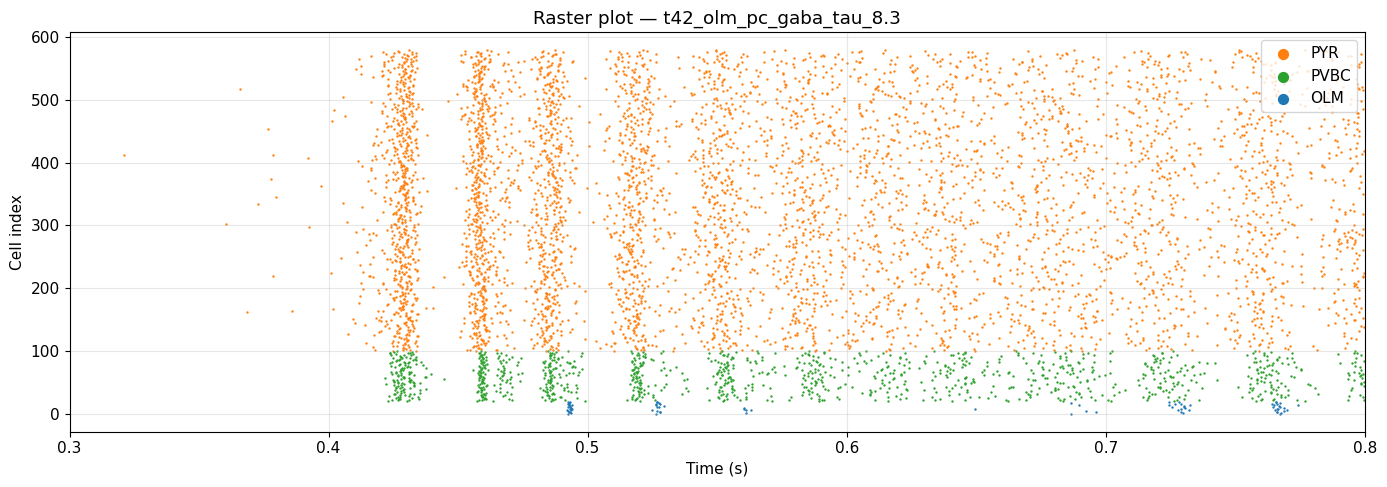

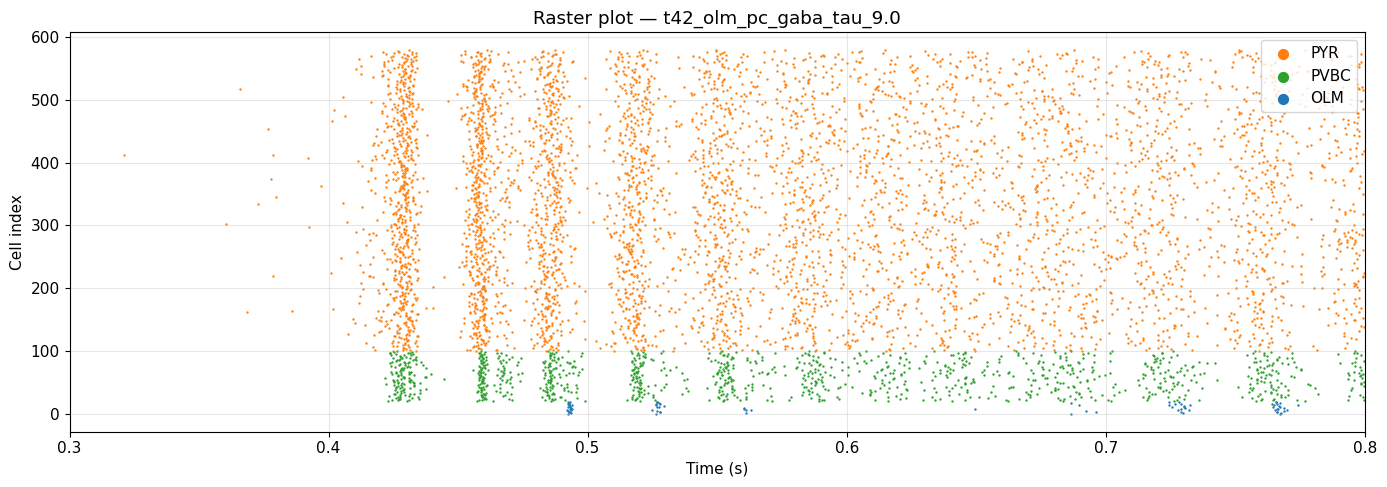

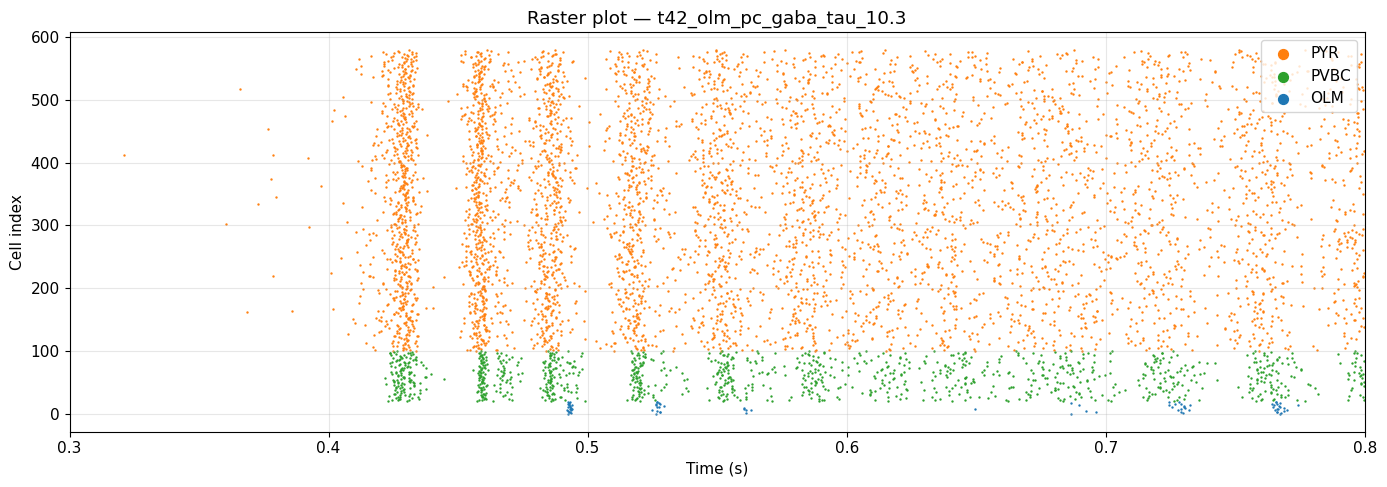

In [ ]:
# Plot raster for each loaded run
for label, data in runs.items():
    cfg = data['simConfig']
    pops = data['populations']
    starttime = cfg.get('starttime', 300)

    fig, ax = plt.subplots(figsize=(14, 5))

    for pop_name in ['PYR_pop', 'PVBC_pop', 'OLM_pop']:
        t, ids = get_pop_spikes(data, pop_name)
        ax.scatter(t / 1000, ids, s=0.5, c=POP_COLORS[pop_name],
                   label=POP_LABELS[pop_name], rasterized=True)

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Cell index')
    ax.set_title(f'Raster plot — {label}')
    ax.legend(loc='upper right', markerscale=10)
    ax.set_xlim(starttime / 1000, cfg['duration'] / 1000)
    plt.tight_layout()
    plt.show()


## Level 2 — Population firing rates and Power Spectral Density

Spike trains are binned (4 ms bins → 250 Hz sampling rate) and converted to
population firing rates. The PSD is computed using Welch's method.

This reproduces the analysis shown in Fig 2E-F of Ponzi et al. (2023).
Key features to look for:
- **Theta peak** (~4–5 Hz) — strongest in OLM
- **Gamma peak** (~25 Hz) — visible in all populations

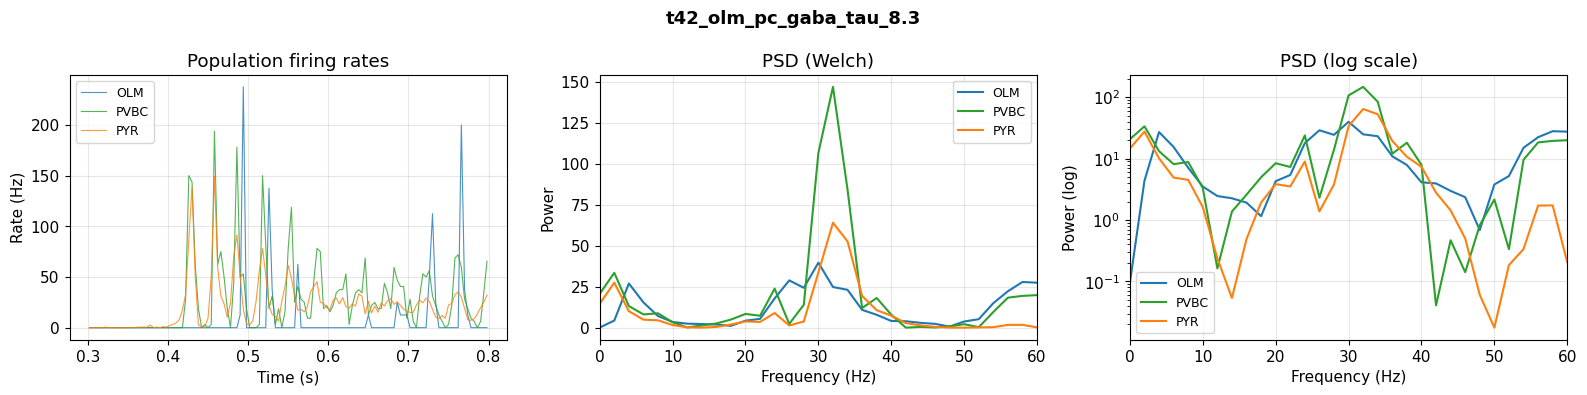

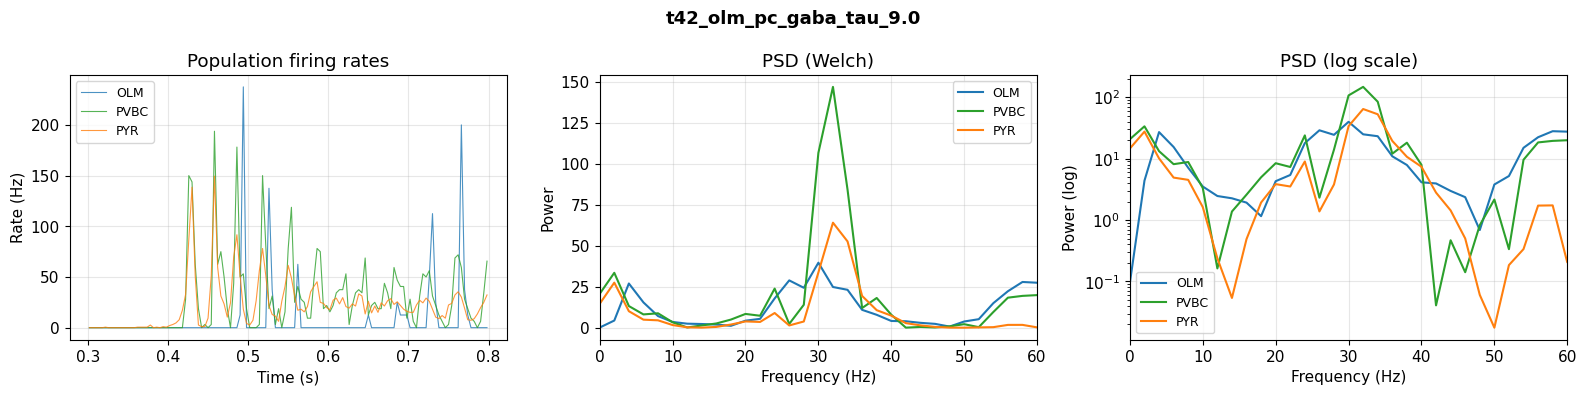

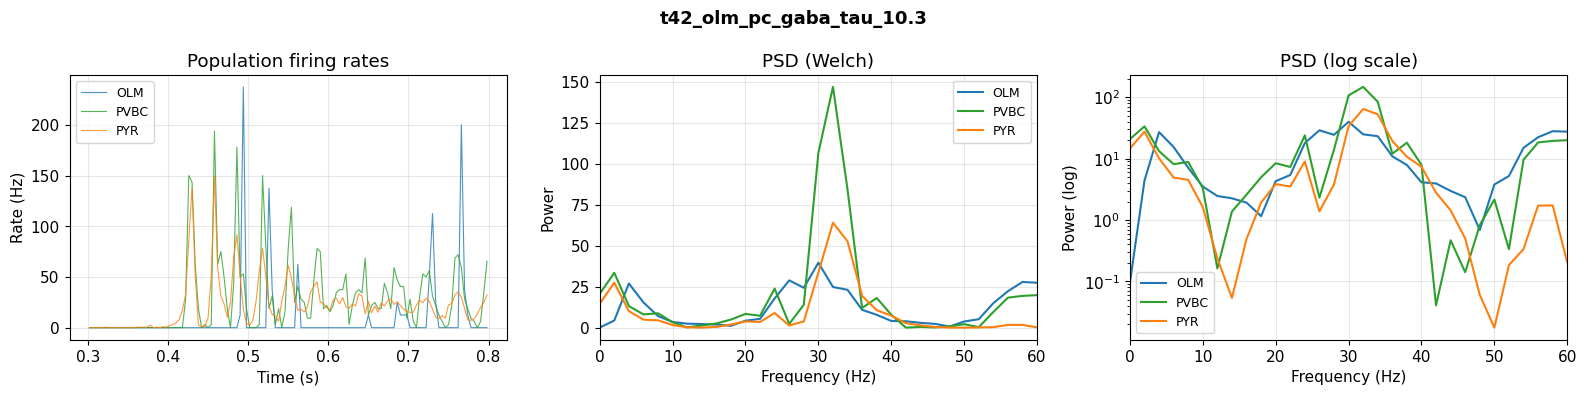

In [ ]:
BIN_MS = 4  # 4 ms bins → 250 Hz (matches project analysis defaults)

for label, data in runs.items():
    cfg = data['simConfig']
    pops = data['populations']
    starttime = cfg.get('starttime', 300)
    duration = cfg['duration']

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(f'{label}', fontsize=13, fontweight='bold')

    # --- Panel 1: Population firing rates ---
    ax = axes[0]
    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        t_sec, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)
        ax.plot(t_sec, rate, c=POP_COLORS[pop_name], label=POP_LABELS[pop_name], alpha=0.8, lw=0.8)

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Rate (Hz)')
    ax.set_title('Population firing rates')
    ax.legend(fontsize=9)

    # --- Panel 2: PSD (linear y) ---
    ax = axes[1]
    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        _, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)
        nperseg = min(256, len(rate))
        noverlap = min(128, nperseg - 1)

        freqs, psd = signal.welch(
            rate,
            fs=fs,
            nperseg=nperseg,
            noverlap=noverlap,
            scaling="density"
        )

        ax.plot(freqs, psd, c=POP_COLORS[pop_name], label=POP_LABELS[pop_name])

    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power')
    ax.set_title('PSD (Welch)')
    ax.set_xlim(0, 60)
    ax.legend(fontsize=9)

    # --- Panel 3: PSD (log y) ---
    ax = axes[2]
    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        _, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)
        nperseg = min(256, len(rate))
        noverlap = min(128, nperseg - 1)

        freqs, psd = signal.welch(
            rate,
            fs=fs,
            nperseg=nperseg,
            noverlap=noverlap,
            scaling="density"
        )

        ax.semilogy(freqs, psd, c=POP_COLORS[pop_name], label=POP_LABELS[pop_name])

    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power (log)')
    ax.set_title('PSD (log scale)')
    ax.set_xlim(0, 60)
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()


## 4. Level 2 — Population firing rates and Power Spectral Density

Spike trains are binned (4 ms bins → 250 Hz sampling rate) and converted to
population firing rates. The PSD is computed using Welch's method.

This reproduces the analysis shown in Fig 2E-F of Ponzi et al. (2023).
Key features to look for:
- **Theta peak** (~4–5 Hz) — strongest in OLM
- **Gamma peak** (~25 Hz) — visible in all populations

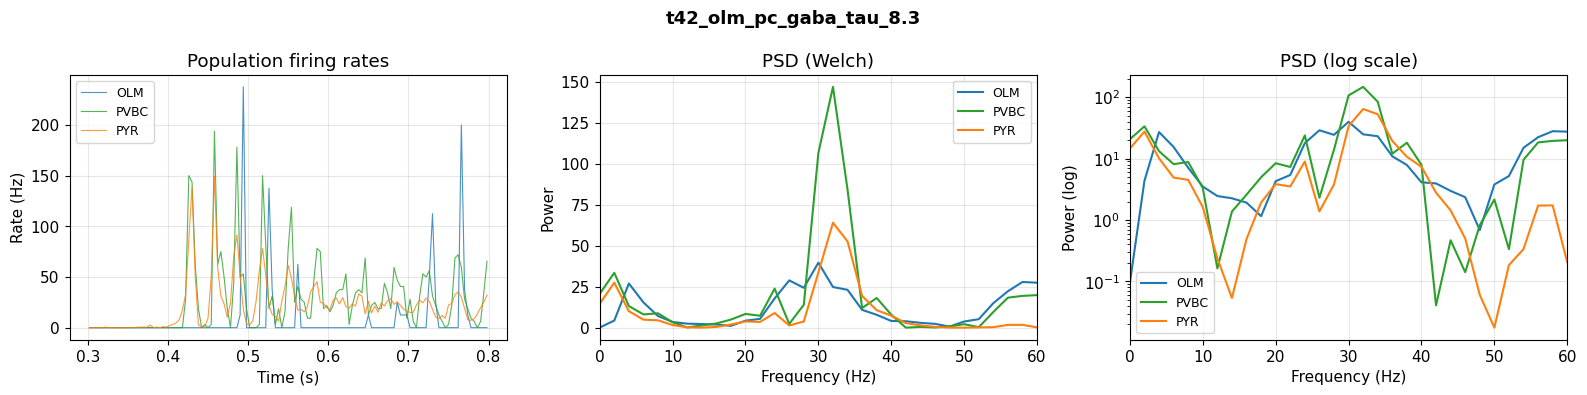

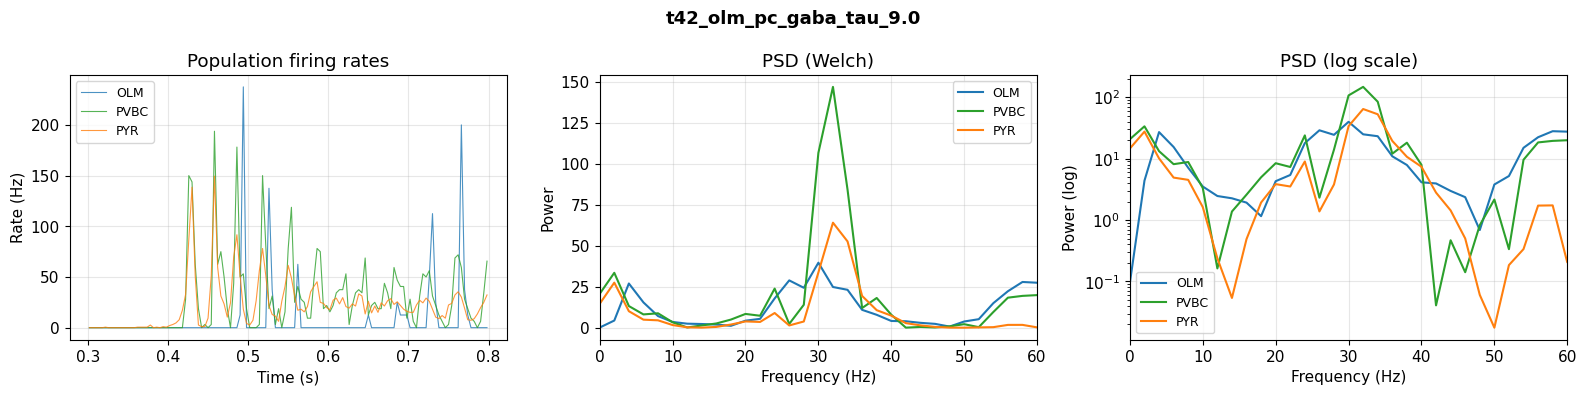

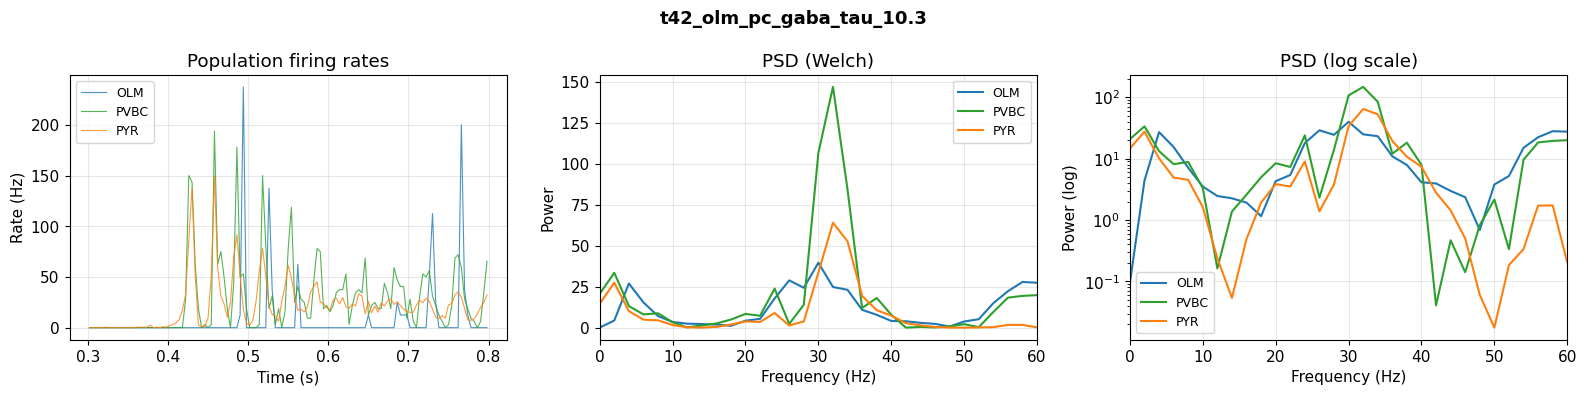

In [ ]:
BIN_MS = 4  # 4 ms bins → 250 Hz (matches project analysis defaults)

for label, data in runs.items():
    cfg = data['simConfig']
    pops = data['populations']
    starttime = cfg.get('starttime', 300)
    duration = cfg['duration']

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(f'{label}', fontsize=13, fontweight='bold')

    # --- Panel 1: Population firing rates ---
    ax = axes[0]
    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        t_sec, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)
        ax.plot(t_sec, rate, c=POP_COLORS[pop_name], label=POP_LABELS[pop_name], alpha=0.8, lw=0.8)

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Rate (Hz)')
    ax.set_title('Population firing rates')
    ax.legend(fontsize=9)

    # --- Panel 2: PSD (linear y) ---
    ax = axes[1]
    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        _, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)
        nperseg = min(256, len(rate))
        noverlap = min(128, nperseg - 1)

        freqs, psd = signal.welch(
            rate,
            fs=fs,
            nperseg=nperseg,
            noverlap=noverlap,
            scaling="density"
        )
        ax.plot(freqs, psd, c=POP_COLORS[pop_name], label=POP_LABELS[pop_name])

    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power')
    ax.set_title('PSD (Welch)')
    ax.set_xlim(0, 60)
    ax.legend(fontsize=9)

    # --- Panel 3: PSD (log y) ---
    ax = axes[2]
    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        _, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)
        nperseg = min(256, len(rate))
        noverlap = min(128, nperseg - 1)

        freqs, psd = signal.welch(
            rate,
            fs=fs,
            nperseg=nperseg,
            noverlap=noverlap,
            scaling="density"
        )
        ax.semilogy(freqs, psd, c=POP_COLORS[pop_name], label=POP_LABELS[pop_name])

    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power (log)')
    ax.set_title('PSD (log scale)')
    ax.set_xlim(0, 60)
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()


## 5. Level 3 — Phase-Amplitude Coupling (PAC)

PAC measures how the amplitude of high-frequency (gamma) oscillations is
modulated by the phase of low-frequency (theta) oscillations.

We compute a **comodulogram** using `pactools`, scanning:
- Phase frequencies: 1–10 Hz (theta range)
- Amplitude frequencies: 15–50 Hz (low gamma range)

This reproduces the analysis shown in Fig 2G of Ponzi et al. (2023).
Strong PAC appears as a warm-coloured blob in the comodulogram around
theta ~4–5 Hz × gamma ~25 Hz.


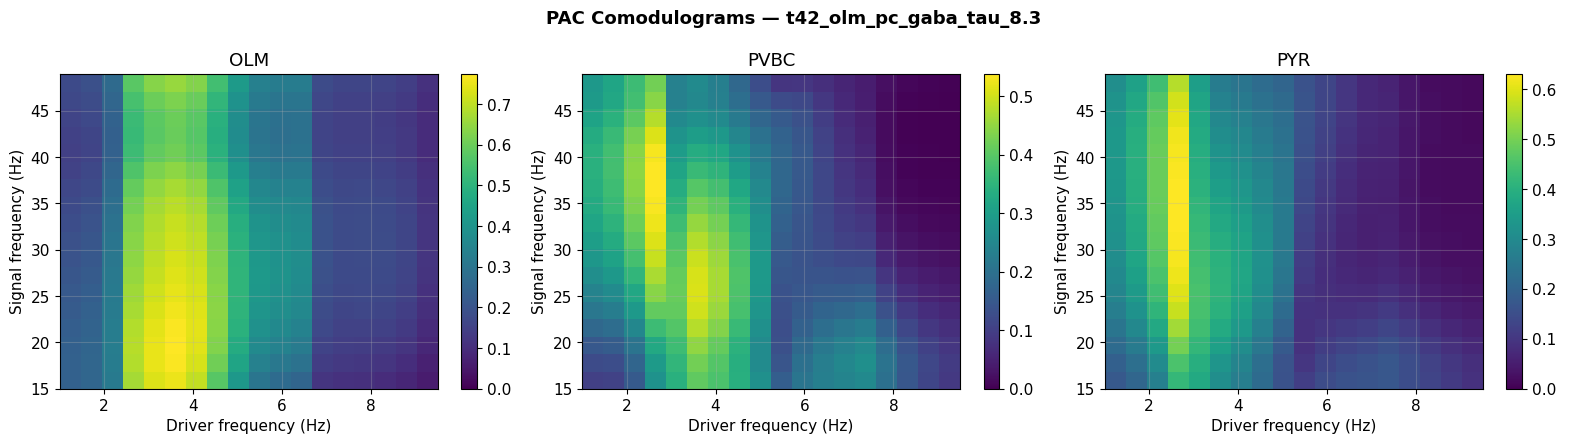

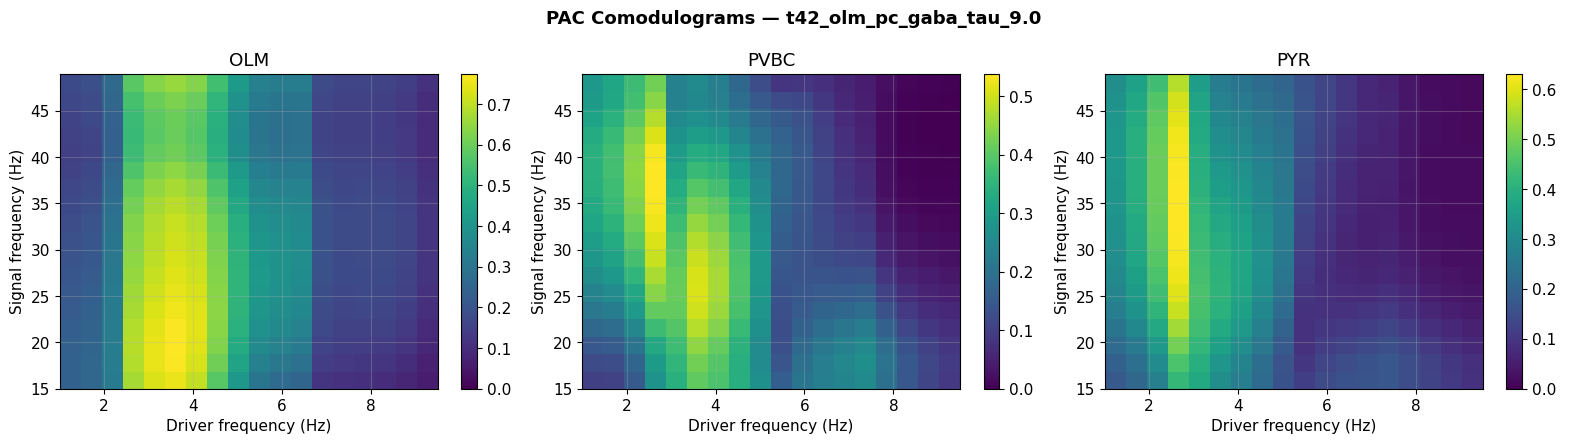

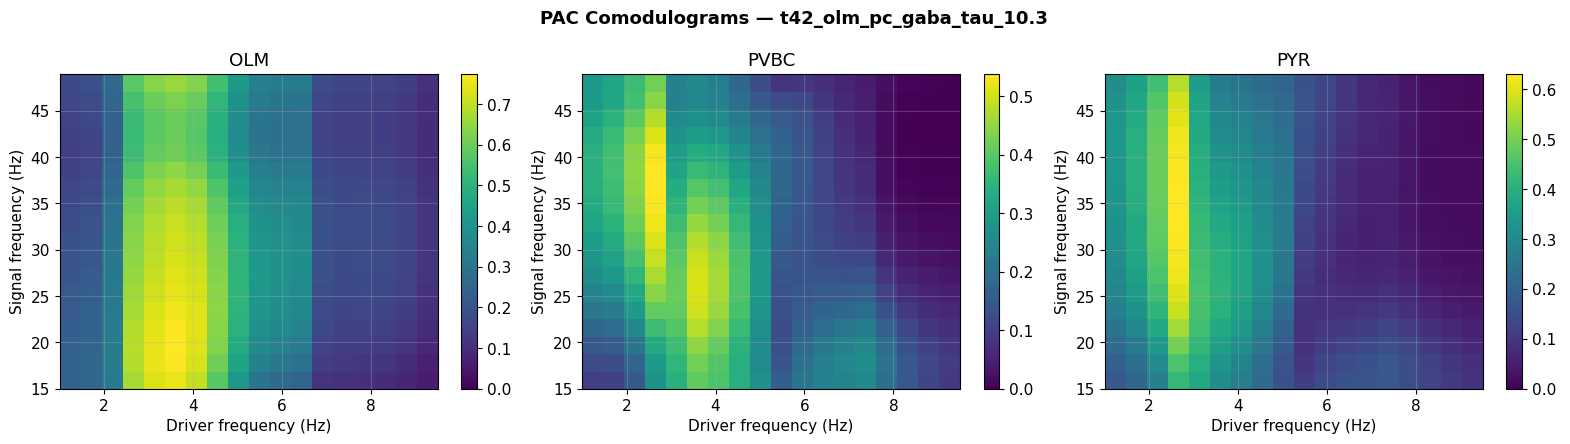

In [ ]:
from pactools import Comodulogram

# PAC parameters (from project analysis defaults)
LOW_FQ_RANGE = np.arange(1, 10, 0.5)   # phase frequencies (theta scan)
HIGH_FQ_RANGE = np.arange(15, 50, 2)   # amplitude frequencies (gamma)

for label, data in runs.items():
    cfg = data['simConfig']
    pops = data['populations']
    starttime = cfg.get('starttime', 300)
    duration = cfg['duration']

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    fig.suptitle(f'PAC Comodulograms — {label}', fontsize=13, fontweight='bold')

    for i, pop_name in enumerate(['OLM_pop', 'PVBC_pop', 'PYR_pop']):
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        _, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)

        # pactools expects a 1D signal
        sig = rate.astype(np.float64)

        estimator = Comodulogram(
            fs=fs,
            low_fq_range=LOW_FQ_RANGE,
            high_fq_range=HIGH_FQ_RANGE,
            method='penny',
            progress_bar=False,
        )
        estimator.fit(sig)

        ax = axes[i]
        estimator.plot(axs=[ax])
        ax.set_title(POP_LABELS[pop_name])

    plt.tight_layout()
    plt.show()


### PAC summary metrics

Extract the peak PAC value and the corresponding theta/gamma frequency pair
for each population and run.


In [ ]:
pac_summary = []

for label, data in runs.items():
    cfg = data['simConfig']
    pops = data['populations']
    starttime = cfg.get('starttime', 300)
    duration = cfg['duration']

    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        spkt, _ = get_pop_spikes(data, pop_name)
        n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
        _, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)

        sig = rate.astype(np.float64)

        estimator = Comodulogram(
            fs=fs,
            low_fq_range=LOW_FQ_RANGE,
            high_fq_range=HIGH_FQ_RANGE,
            method='penny',
            progress_bar=False,
        )
        estimator.fit(sig)

        comod = estimator.comod_
        pac_max = comod.max()
        pac_mean = comod.mean()
        idx = np.unravel_index(comod.argmax(), comod.shape)
        peak_theta = LOW_FQ_RANGE[idx[0]]
        peak_gamma = HIGH_FQ_RANGE[idx[1]]

        pac_summary.append({
            'run': label,
            'population': POP_LABELS[pop_name],
            'pac_max': round(float(pac_max), 6),
            'pac_mean': round(float(pac_mean), 6),
            'peak_theta_hz': float(peak_theta),
            'peak_gamma_hz': float(peak_gamma),
        })

# Display as a table
try:
    import pandas as pd
    df_pac = pd.DataFrame(pac_summary)
    display(df_pac)
except ImportError:
    for row in pac_summary:
        print(row)


,run,population,pac_max,pac_mean,peak_theta_hz,peak_gamma_hz
0,t42_olm_pc_gaba_tau_8.3,OLM,0.774672,0.349552,3.5,19.0
1,t42_olm_pc_gaba_tau_8.3,PVBC,0.538621,0.218551,2.5,37.0
2,t42_olm_pc_gaba_tau_8.3,PYR,0.630996,0.218426,2.5,35.0
3,t42_olm_pc_gaba_tau_9.0,OLM,0.774672,0.349552,3.5,19.0
4,t42_olm_pc_gaba_tau_9.0,PVBC,0.538621,0.218551,2.5,37.0
5,t42_olm_pc_gaba_tau_9.0,PYR,0.630996,0.218426,2.5,35.0
6,t42_olm_pc_gaba_tau_10.3,OLM,0.774672,0.349552,3.5,19.0
7,t42_olm_pc_gaba_tau_10.3,PVBC,0.538621,0.218551,2.5,37.0
8,t42_olm_pc_gaba_tau_10.3,PYR,0.630996,0.218426,2.5,35.0


## 6. Level 4 — Compare across parameter values

If you loaded multiple runs (different values of the swept parameter),
this section overlays their PSDs and compares PAC metrics side by side.


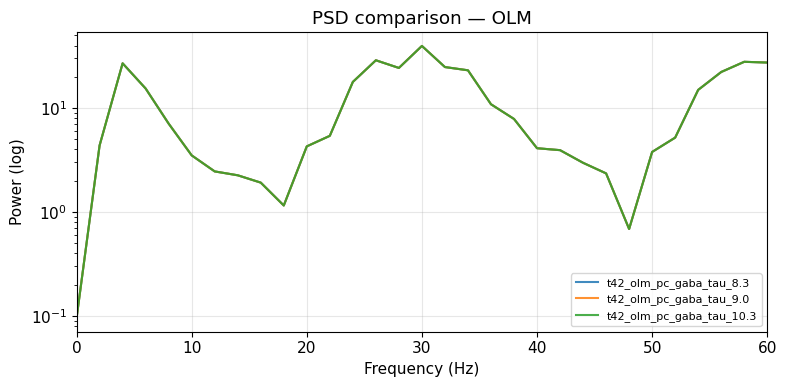

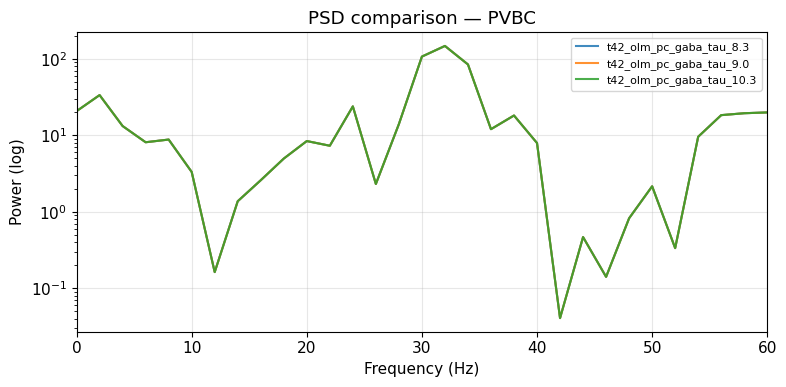

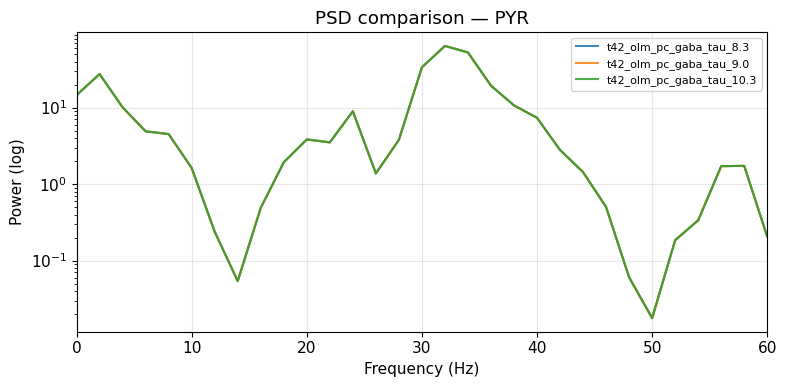

In [ ]:
if len(runs) < 2:
    print("Only 1 run loaded — load multiple runs to enable comparison.")
    print("Go back to Section 2 and add more file paths.")
else:
    # --- PSD comparison ---
    for pop_name in ['OLM_pop', 'PVBC_pop', 'PYR_pop']:
        fig, ax = plt.subplots(figsize=(8, 4))

        for label, data in runs.items():
            cfg = data['simConfig']
            pops = data['populations']
            starttime = cfg.get('starttime', 300)
            duration = cfg['duration']

            spkt, _ = get_pop_spikes(data, pop_name)
            n_cells = pops[pop_name]['end'] - pops[pop_name]['start']
            _, rate, fs = spikes_to_rate(spkt, n_cells, duration, starttime, BIN_MS)
            nperseg = min(256, len(rate))
            noverlap = min(128, nperseg - 1)

            freqs, psd = signal.welch(
                rate,
                fs=fs,
                nperseg=nperseg,
                noverlap=noverlap,
                scaling="density"
            )

            ax.semilogy(freqs, psd, label=label, alpha=0.85)

        ax.set_xlabel('Frequency (Hz)')
        ax.set_ylabel('Power (log)')
        ax.set_title(f'PSD comparison — {POP_LABELS[pop_name]}')
        ax.set_xlim(0, 60)
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.show()


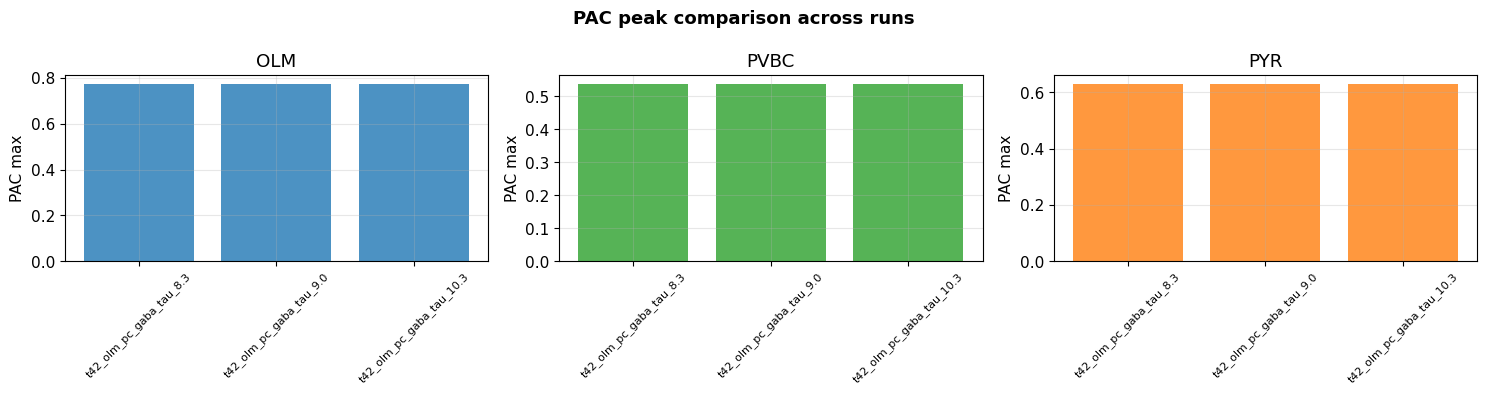


PAC Summary Table:


pac_max                     peak_gamma_hz        \
population                     OLM      PVBC       PYR           OLM  PVBC   
run                                                                          
t42_olm_pc_gaba_tau_10.3  0.774672  0.538621  0.630996          19.0  37.0   
t42_olm_pc_gaba_tau_8.3   0.774672  0.538621  0.630996          19.0  37.0   
t42_olm_pc_gaba_tau_9.0   0.774672  0.538621  0.630996          19.0  37.0   

                               peak_theta_hz            
population                 PYR           OLM PVBC  PYR  
run                                                     
t42_olm_pc_gaba_tau_10.3  35.0           3.5  2.5  2.5  
t42_olm_pc_gaba_tau_8.3   35.0           3.5  2.5  2.5  
t42_olm_pc_gaba_tau_9.0   35.0           3.5  2.5  2.5

In [ ]:
if len(runs) >= 2 and pac_summary:
    try:
        import pandas as pd
        df = pd.DataFrame(pac_summary)

        # --- PAC max comparison bar chart ---
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        fig.suptitle('PAC peak comparison across runs', fontsize=13, fontweight='bold')

        for i, pop in enumerate(['OLM', 'PVBC', 'PYR']):
            ax = axes[i]
            sub = df[df['population'] == pop]
            bars = ax.bar(range(len(sub)), sub['pac_max'],
                         tick_label=sub['run'].values,
                         color=POP_COLORS[f'{pop}_pop'], alpha=0.8)
            ax.set_ylabel('PAC max')
            ax.set_title(pop)
            ax.tick_params(axis='x', rotation=45, labelsize=8)

        plt.tight_layout()
        plt.show()

        # --- Summary table ---
        print("\nPAC Summary Table:")
        pivot = df.pivot_table(index='run', columns='population',
                               values=['pac_max', 'peak_theta_hz', 'peak_gamma_hz'])
        display(pivot)

    except ImportError:
        print("Install pandas for comparison tables: pip install pandas")
